In [8]:
# Run package installation manually only when needed; restart the kernel afterward.
# %pip install --no-cache-dir --force-reinstall torch --index-url https://download.pytorch.org/whl/cpu


In [9]:
import pandas as pd
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [10]:
taxi = pd.read_parquet("./../taxi_trips.parquet")
taxi

,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
187173,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855
179655,0.085681,0.306079,-0.226274,0.124111,10.680277,0.778703,-1.047619,-0.311290
120048,-0.555533,-0.934806,-0.022489,-0.548561,5.716184,-1.183016,-1.047619,1.316504
62587,0.069718,0.035804,0.258900,0.317284,4.266709,-0.908008,0.481657,0.018144
212063,-0.234482,0.074616,0.115836,0.258310,11.629685,1.066806,-0.537860,0.521985
...,...,...,...,...,...,...,...,...
519591,-0.853230,-0.623528,-1.257638,-0.858561,5.449624,1.548723,0.991416,1.665317
342999,0.623131,0.373217,-0.558609,-0.119350,14.777549,-1.714696,0.481657,-1.745299
157477,-0.226796,-0.595202,-0.527212,-1.051594,8.531511,-1.976608,1.501174,0.056901
432901,-0.226796,0.056775,1.005321,-1.571717,20.489817,1.111331,-0.028101,0.812663


In [22]:
#hyperparam
bs = 128
lr = 5e-4
layers = [128, 64, 32]
epochs = 100
print_every_t = 1

In [27]:
pred = "trip_duration"
X = taxi.drop(columns=[pred]).to_numpy(dtype=np.float32)
Y = taxi[pred].to_numpy(dtype=np.float32).reshape(-1, 1)
X_tra, X_mid, Y_tra, Y_mid = train_test_split(X, Y, test_size=0.20)
X_val, X_tes, Y_val, Y_tes = train_test_split(X_mid, Y_mid, test_size = 0.50)

def tensorify(X, Y):
    return TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32))

tra_ld = DataLoader(tensorify(X_tra, Y_tra), batch_size=bs, shuffle=True)
val_ld = DataLoader(tensorify(X_val, Y_val), batch_size=bs, shuffle=True)
tes_ld = DataLoader(tensorify(X_tes, Y_tes), batch_size=bs, shuffle=True)

modules = []
in_features = X_tra.shape[1]
for width in layers:
    modules.append(nn.Linear(in_features, width))
    modules.append(nn.ReLU())
    in_features = width
modules.append(nn.Linear(in_features, 2))

model = nn.Sequential(*modules)

def los(output, y):
    mu = output[:, 0:1]
    log_var = output[:, 1:2].clamp(-8, 8)
    return 0.5 * (log_var + (y - mu).square() * torch.exp(-log_var)).mean()
opt = torch.optim.Adam(model.parameters(), lr=lr)

In [28]:
@torch.no_grad()
def eval(ld):
    model.eval()
    tot_los = 0.0
    for x, y in ld:
        tot_los += los(model(x), y).item() * len(x)
    return tot_los / len(ld.dataset)

best_val_loss = float("inf")
val_losses = []
best_model = None

for epo in range(epochs):
    model.train()
    for x, y in tra_ld:
        opt.zero_grad()
        loss = los(model(x), y)
        loss.backward()
        opt.step()

    val_loss = eval(val_ld)
    val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model = {k: v.detach().clone() for k, v in model.state_dict().items()}
        

    if (epo + 1) % print_every_t == 0:
        print(f"epoch: {epo + 1}, val_loss: {val_loss}")


epoch: 1, val_loss: 1.8596179074333044
epoch: 2, val_loss: 1.7898821301793155
epoch: 3, val_loss: 1.7739814423066635
epoch: 4, val_loss: 1.7615686672189927
epoch: 5, val_loss: 1.7573761956282576
epoch: 6, val_loss: 1.7400840041243737
epoch: 7, val_loss: 1.7372363629535577
epoch: 8, val_loss: 1.7548049375282502
epoch: 9, val_loss: 1.7454860067654447
epoch: 10, val_loss: 1.719911720451932
epoch: 11, val_loss: 1.7277541079501597
epoch: 12, val_loss: 1.7198199441651312
epoch: 13, val_loss: 1.7106745880752838
epoch: 14, val_loss: 1.7099582639445026
epoch: 15, val_loss: 1.778245466523475
epoch: 16, val_loss: 1.7322752741617022
epoch: 17, val_loss: 1.6998592648279836
epoch: 18, val_loss: 1.6907063451312854
epoch: 19, val_loss: 1.6989119234814616
epoch: 20, val_loss: 1.6903168891542064
epoch: 21, val_loss: 1.7008222458321822
epoch: 22, val_loss: 1.69052345363359
epoch: 23, val_loss: 1.6845351584330408
epoch: 24, val_loss: 1.7092238680633975
epoch: 25, val_loss: 1.6933250000843196
epoch: 26, va

In [29]:
model.load_state_dict(best_model)
test_loss = eval(tes_ld)

model.eval()
with torch.no_grad():
    output = model(torch.tensor(X_tes, dtype=torch.float32))
    pred_mean = output[:, 0:1]
    pred_var = output[:, 1:2].clamp(-10, 10).exp()

test_loss


1.8125028655312079

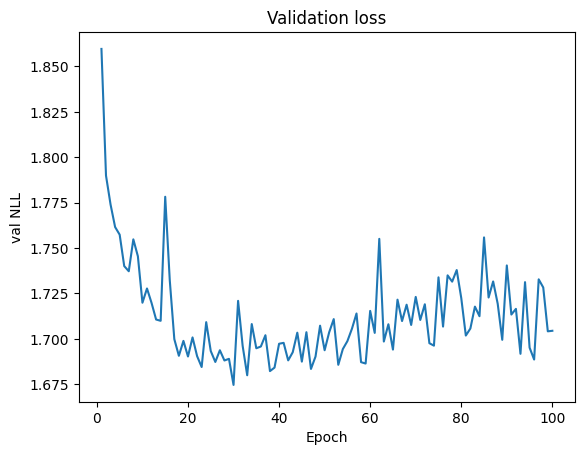

In [ ]:
#Validation loss graph: as we can see, the network was probably overtrained, having reached a minimum in validation loss around epoch 25-30 and only increasing afterwards, probably overfitting. 
#We were able to save down that earlier model from epoch 25-30 and use that as the final model.

import matplotlib.pyplot as plt

irreducible_error = pred_var.mean().item()


plt.plot(range(1, len(val_losses) + 1), val_losses)
plt.xlabel("Epoch")
plt.ylabel("val NLL")
plt.title("Validation loss")
plt.show()


In [ ]:
##comparison to a variety of baseline models on the held-out test set, to demonstrate the gain of the MLP over other models
#an example baseline is a simple linear model
#we can also try a boosted tree
#(These only are comparing the accuracy wrt conditional mean, not accuracy wrt to the conditional variance)
#The MLP performs the best, though the gradient-boosted tree is actually quite good as well, while being much faster

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

lin = LinearRegression()
lin.fit(X_tra, Y_tra)

boost = HistGradientBoostingRegressor(
    max_iter=200,
    max_leaf_nodes=20,
    early_stopping=True,
    random_state=67,
)

boost.fit(X_tra, Y_tra.ravel())
boost_pred = boost.predict(X_tes)

base_pred = np.full_like(Y_tes, Y_tra.mean())
lin_pred = lin.predict(X_tes)
mlp_pred = pred_mean.detach().numpy()

print("constant mse:", np.mean((Y_tes - base_pred) ** 2))
print("linear mse:", np.mean((Y_tes - lin_pred) ** 2))
print("boost mse:", np.mean((Y_tes.ravel() - boost_pred) ** 2))
print("mlp mse:", np.mean((Y_tes - mlp_pred) ** 2))

constant mse: 61.88718
linear mse: 58.389683
boost mse: 18.399716404641598
mlp mse: 15.714155


In [ ]:
#Testing the accuracy of the model in predicting <45 minutes, using the conditional mean and variance and assuming normality.
#As we can see, the model achieves a Brier score of 0.00309, which beats the 0.00470 constant probability estimate (only based on Y, without using X)

from scipy.special import ndtr

mu = pred_mean.detach().numpy().ravel()
var = pred_var.detach().numpy().ravel()

prob = ndtr((45 - mu) / np.sqrt(var))
actual = (Y_tes.ravel() < 45).astype(int)

brier = np.mean((prob - actual) ** 2)
acc = np.mean((prob >= 0.5) == actual)

print("brier:", brier)
print("accuracy:", acc)
print("always under 45 accuracy:", actual.mean())

base_prob = np.mean(Y_tra.ravel() < 45)
base_brier = np.mean((base_prob - actual) ** 2)

print("baseline brier:", base_brier)

brier: 0.0030858428691063053
accuracy: 0.9965237986095195
always under 45 accuracy: 0.9952822981129192
baseline brier: 0.00469552053148897


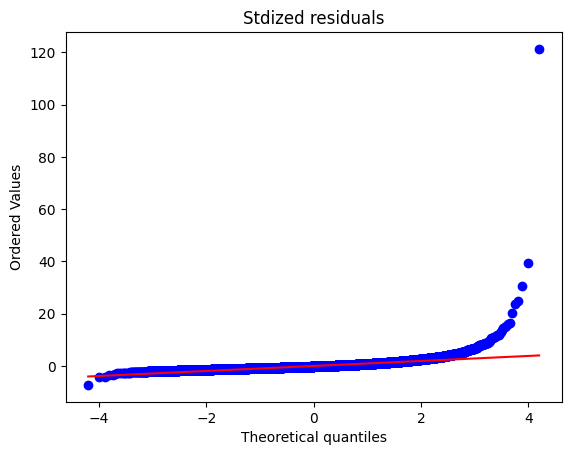

mean: -0.025238028
std: 1.1778804
within 1 std: 0.7762243104897242
within 2 std: 0.9600045840018336


In [ ]:
#Normality test: the distribution is approximately skewed, with unusually high residuals to the right end of the distribution rel. to normal.
#This suggests some kind of concave transformation could further improve this model

import matplotlib.pyplot as plt
from scipy import stats

res = (Y_tes.ravel() - mu) / np.sqrt(var)

stats.probplot(res, dist="norm", plot=plt)
plt.title("Stdized residuals")
plt.show()

print("mean:", res.mean())
print("std:", res.std())
print("within 1 std:", np.mean(np.abs(res) < 1))
print("within 2 std:", np.mean(np.abs(res) < 2))